In [1]:
# Imports y carga de datos
import sys; sys.path.append("..")
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
from src.datos import cargar_inventario, a_gris
from skimage import filters, morphology, measure
from skimage.metrics import structural_similarity as ssim, peak_signal_noise_ratio as psnr
from skimage.transform import resize


df = cargar_inventario()
print(len(df), "imágenes")

3427 imágenes


## 1. Suavizado para reducir ruido

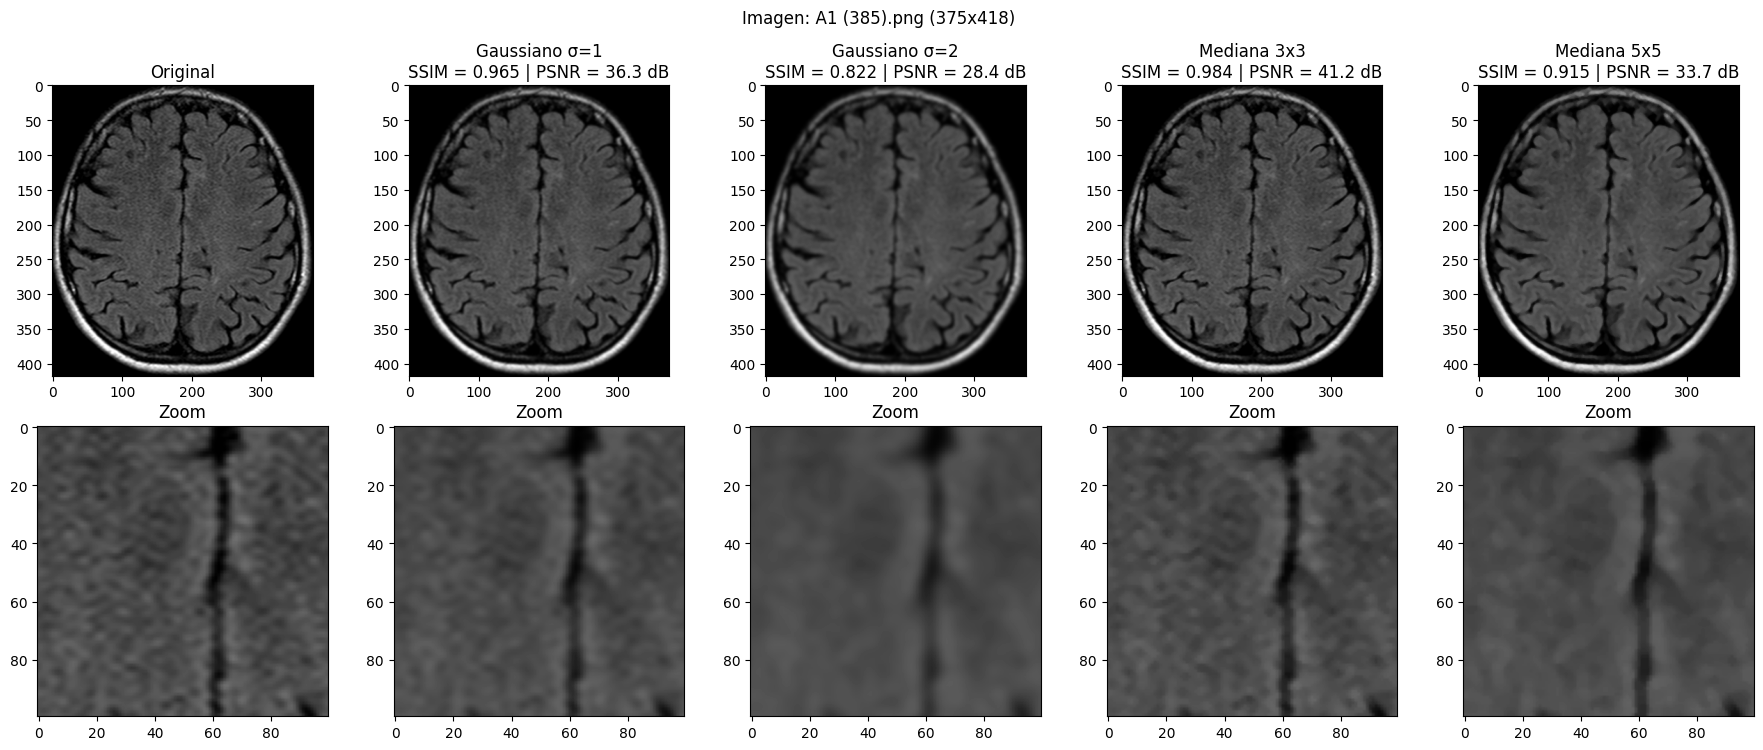

In [2]:
# Suavizado de la imágen con filtros Gaussiano y Mediana 
r = df[(df["Clase"] == "MS") & (df["Corte"] == "Axial")].sample(1).iloc[0]
img = a_gris(r["ruta"]).astype(float)

versiones = {
    "Original":       img,
    "Gaussiano σ=1":  ndi.gaussian_filter(img, 1),
    "Gaussiano σ=2":  ndi.gaussian_filter(img, 2),
    "Mediana 3x3":    ndi.median_filter(img, size=3),
    "Mediana 5x5":    ndi.median_filter(img, size=5),
}

h, w = img.shape
zoom = (slice(h // 3, h // 3 + 100), slice(w // 3, w // 3 + 100))
fig, axs = plt.subplots(2, 5, figsize=(18, 7.5))
for j, (nombre, im) in enumerate(versiones.items()):
    titulo = nombre
    if nombre != "Original":
        titulo += f"\nSSIM = {ssim(img, im, data_range=255):.3f} | PSNR = {psnr(img, im, data_range=255):.1f} dB"
    axs[0, j].imshow(im, cmap="gray", vmin=0, vmax=255)
    axs[0, j].set_title(titulo)
    axs[1, j].imshow(im[zoom], cmap="gray", vmin=0, vmax=255)
    axs[1, j].set_title("Zoom")
fig.suptitle(f"Imagen: {r['ruta'].name} ({w}x{h})")
plt.tight_layout()
plt.show()

&ensp; Comparamos dos familias de filtros espaciales sobre un mismo corte: gaussiano (σ = 1 y σ = 2) y mediana (ventanas de 3×3 y 5×5). Elegimos la **mediana 3×3** por los siguientes motivos:

- **Preserva mejor los bordes.** El gaussiano es un filtro lineal que promedia a todos los vecinos con pesos fijos, por lo que difumina las transiciones entre estructuras. La mediana es no lineal: reemplaza cada píxel por el valor central de su vecindad y, en un borde, tiende a conservarlo. En la ampliación se aprecia que con mediana 3×3 los contornos (por ejemplo, la cisura interhemisférica) se ven apenas más definidos que con gaussiano de σ = 1, y claramente más que con σ = 2.

- **Cuida el contraste de las lesiones.** Las lesiones de EM son manchas pequeñas e hiperintensas. Un filtro que promedia con demasiada fuerza (gaussiano con σ grande, o mediana con ventana grande) reduce su contraste y puede hacerlas desaparecer. Con la ventana mínima (3×3) el efecto sobre ellas es el menor posible.

- **El ruido de la RM no es gaussiano aditivo.** En imágenes de magnitud el ruido sigue una distribución de Rice, con valores atípicos aislados. La mediana es robusta frente a esos valores, mientras que el promedio ponderado del gaussiano los reparte entre los vecinos.

- **No genera niveles de gris nuevos.** Cada salida es un valor que ya existía en la vecindad.

**Métricas.** Como referencia cuantitativa calculamos SSIM y PSNR de cada versión suavizada respecto de la original. La mediana 3×3 obtiene los valores más altos en la mayoría de los cortes (por ejemplo, SSIM = 0,997 y PSNR = 49,8 dB en un corte axial de MS), lo que indica que es el filtro que menos altera la estructura de la imagen. Estas métricas miden cuánto cambia la imagen, no cuánto ruido se elimina. Dado que las imágenes del dataset ya parecen venir suavizadas de origen, el efecto de cualquier filtro es pequeño, y el suavizado cumple sobre todo la función de estabilizar las etapas posteriores basadas en umbrales. La ventana de 5×5 se descartó por suavizar de más.

## 2. Máscara cerebral

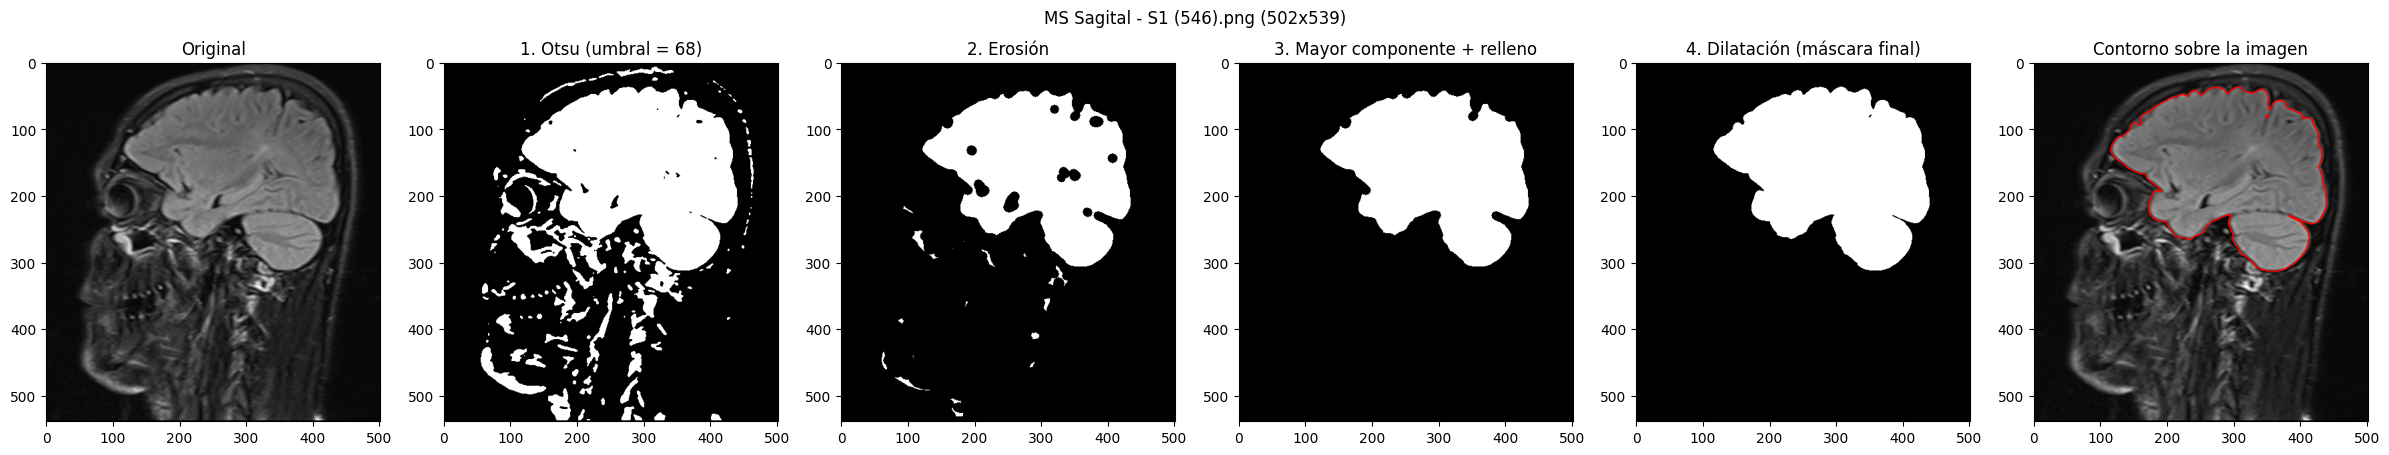

In [3]:
# Ahora creamos una máscara para quedarnos únicamente con el cerebro (quitamos el cráneo y demás estructuras)
RADIO = 6   # radio de erosión/dilatación (px)

r = df.sample(1).iloc[0]
img = a_gris(r["ruta"])
s = ndi.median_filter(img.astype(float), size=3) #Filtro de mediana 3x3

umbral = filters.threshold_otsu(s)
m1 = s > umbral                                          # 1. máscara de Otsu
est = morphology.disk(RADIO)
m2 = ndi.binary_erosion(m1, structure=est)               # 2. erosión
lab = measure.label(m2)
assert lab.max() > 0, "La erosión borró todo. Se requiere bajar el RADIO"
m3 = lab == (np.argmax(np.bincount(lab.ravel())[1:]) + 1)   # 3. componente más grande
m3 = ndi.binary_fill_holes(m3)                           #    + relleno de huecos
m4 = ndi.binary_dilation(m3, structure=est)              # 4. dilatación = máscara final

fig, axs = plt.subplots(1, 6, figsize=(24, 4.5))
axs[0].imshow(img, cmap="gray", vmin=0, vmax=255);  axs[0].set_title("Original")
axs[1].imshow(m1, cmap="gray");  axs[1].set_title(f"1. Otsu (umbral = {umbral:.0f})")
axs[2].imshow(m2, cmap="gray");  axs[2].set_title("2. Erosión")
axs[3].imshow(m3, cmap="gray");  axs[3].set_title("3. Mayor componente + relleno")
axs[4].imshow(m4, cmap="gray");  axs[4].set_title("4. Dilatación (máscara final)")
axs[5].imshow(img, cmap="gray", vmin=0, vmax=255)
axs[5].contour(m4.astype(float), levels=[0.5], colors="r", linewidths=1)
axs[5].set_title("Contorno sobre la imagen")
fig.suptitle(f"{r['Clase']} {r['Corte']} - {r['ruta'].name} ({img.shape[1]}x{img.shape[0]})")
plt.tight_layout()
plt.show()

&ensp; Para restringir el análisis al tejido cerebral únicamente, construimos una máscara binaria en cuatro pasos sobre la imagen suavizada: 

(1) umbralización de Otsu, que separa el tejido del fondo; 

(2) erosión con un elemento estructural circular de radio 6 px, que desconecta el cerebro del cuero cabelludo (el cráneo, oscuro en FLAIR, queda entre ambos); 

(3) selección del componente conexo de mayor área, que se asume que es el cerebro, y relleno de los huecos interiores (ventrículos) con `binary_fill_holes` que rellena pixeles negros rodeados completamente de pixeles blancos;

(4) dilatación con el mismo elemento, para recuperar el tamaño original.

&ensp; En los cortes revisados, axiales y sagitales, la máscara delimita correctamente el cerebro y se comporta bien incluso en cortes con muy poco tejido. En los cortes de la base del cráneo captura solo el cerebelo, que es la estructura de mayor área en ese nivel.

kontrol 40 (11).png: 1 isla(s) conservada(s) de 2


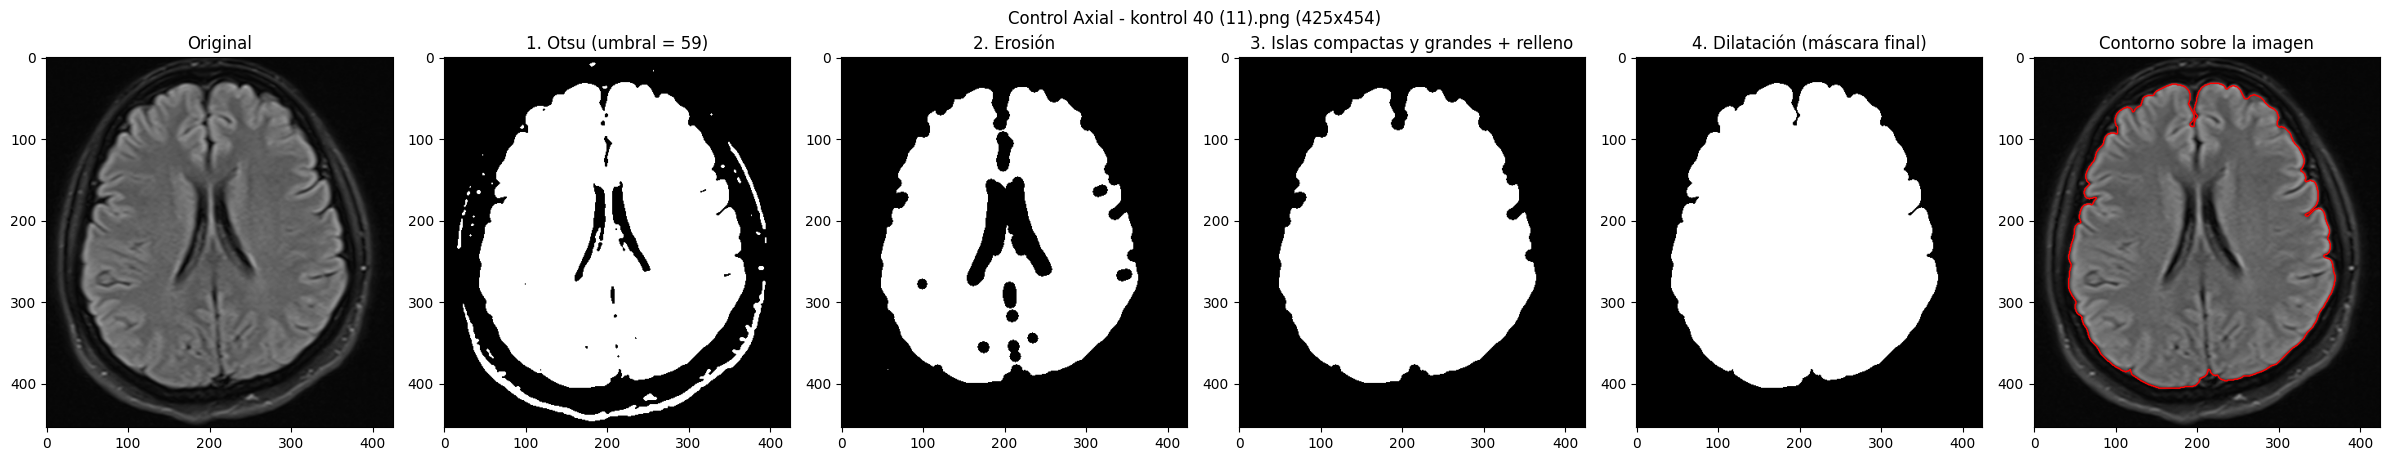

In [4]:
# Segunda versión de la máscara cerebral: conservamos TODAS las islas compactas y grandes (no solo la mayor)
RADIO = 6           # radio de erosión/dilatación (px)
FRAC_AREA = 0.25    # área mínima de una isla, relativa a la mayor isla compacta
SOLIDEZ_MIN = 0.3   # solidez mínima (área / área de la envolvente convexa) para descarta arcos finos como el cuero cabelludo

r = df.sample(1).iloc[0]
# r = df[(df["ruta"].apply(lambda p: p.name) == "A1 (289).png") & (df["Corte"] == "Axial")].iloc[0]   # para probar un corte puntual
img = a_gris(r["ruta"])
s = ndi.median_filter(img.astype(float), size=3)   # filtro de mediana 3x3

umbral = filters.threshold_otsu(s)
m1 = s > umbral                                           # 1. máscara de Otsu
est = morphology.disk(RADIO)
m2 = ndi.binary_erosion(m1, structure=est)                # 2. erosión
lab = measure.label(m2)
assert lab.max() > 0, "La erosión borró todo: bajar el RADIO"

props = measure.regionprops(lab)
compactas = [p for p in props if p.solidity >= SOLIDEZ_MIN]
assert compactas, "Ninguna isla es compacta: corte sin cerebro útil"
amax = max(p.area for p in compactas)
conservar = [p.label for p in compactas if p.area >= FRAC_AREA * amax]
m3 = ndi.binary_fill_holes(np.isin(lab, conservar))       # 3. islas compactas y grandes + relleno de huecos
m4 = ndi.binary_dilation(m3, structure=est)               # 4. dilatación = máscara final
print(f"{r['ruta'].name}: {len(conservar)} isla(s) conservada(s) de {len(props)}")

fig, axs = plt.subplots(1, 6, figsize=(24, 4.5))
axs[0].imshow(img, cmap="gray", vmin=0, vmax=255);  axs[0].set_title("Original")
axs[1].imshow(m1, cmap="gray");  axs[1].set_title(f"1. Otsu (umbral = {umbral:.0f})")
axs[2].imshow(m2, cmap="gray");  axs[2].set_title("2. Erosión")
axs[3].imshow(m3, cmap="gray");  axs[3].set_title("3. Islas compactas y grandes + relleno")
axs[4].imshow(m4, cmap="gray");  axs[4].set_title("4. Dilatación (máscara final)")
axs[5].imshow(img, cmap="gray", vmin=0, vmax=255)
axs[5].contour(m4.astype(float), levels=[0.5], colors="r", linewidths=1)
axs[5].set_title("Contorno sobre la imagen")
fig.suptitle(f"{r['Clase']} {r['Corte']} - {r['ruta'].name} ({img.shape[1]}x{img.shape[0]})")
plt.tight_layout()
plt.show()

&ensp; Hicimos una segunda versión de la máscara cerebral

&ensp; La primera versión conservaba únicamente la isla de mayor área tras la erosión. Esto vimos que funcionaba en los cortes medios, pero fallaba en los cortes altos porque la cisura interhemisférica es ancha, la erosión separa los dos hemisferios en islas distintas, y al quedarnos solo con la mayor se perdía la mitad del cerebro.

&ensp; Al inspeccionar las islas, los dos hemisferios resultaron de área similar (≈ 0,77 de la mayor) y compactos (solidez entre 0,42 y 0,55), mientras que el cuero cabelludo aparece como un arco fino y alargado de solidez muy baja (0,05 a 0,19). La segunda versión conserva entonces **todas las islas compactas (solidez ≥ 0,3) cuya área sea al menos el 25 % de la mayor isla compacta**, y descarta el resto. Si ninguna isla es compacta, se devuelve una máscara vacía (corte sin cerebro útil). Filtrar también la isla mayor evita que, en cortes con poco cerebro, el anillo de cuero cabelludo (que pasa a ser la isla más grande) se conserve por error.

&ensp; Los umbrales se fijaron a partir de dos cortes y se validaron visualmente en unas decenas de cortes axiales y sagitales. 

**Limitación:** en cortes de la base del cráneo la máscara puede incluir estructuras brillantes que no son cerebro (por ejemplo, tejido nasal), que podrían confundirse con lesiones. Podríamos reportar al una tasa de error aproximada sobre una muestra al final del trabajo.

## 3. Normalización de intensidades

Imagen: Control Axial - kontrol 40 (11).png
Dentro de la máscara:  Q1 = 93.0 | mediana = 101.0 | Q3 = 112.0 | IQR = 19.0


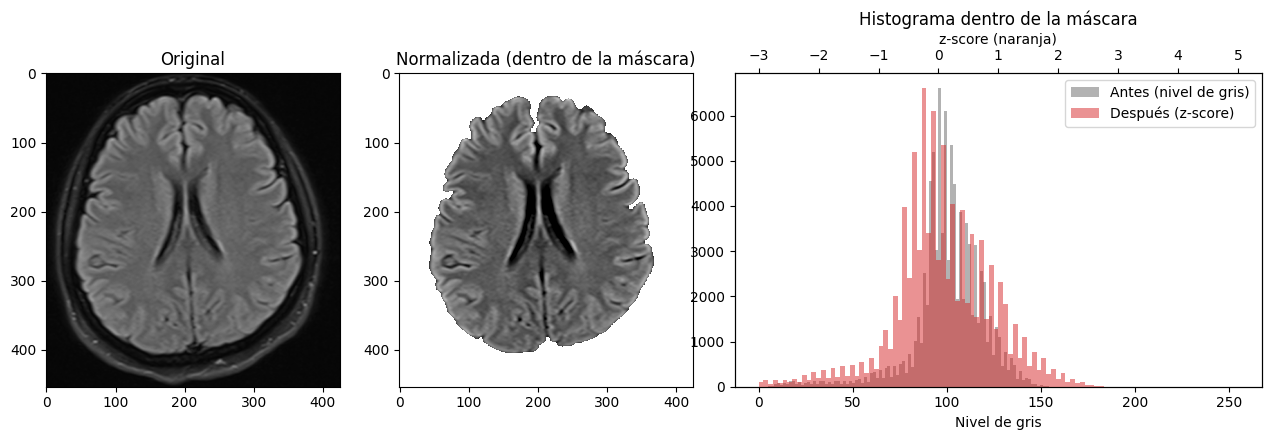

In [5]:
# Normalización: estandarización de niveles de gris

v = img[m4].astype(float)
q1, med, q3 = np.percentile(v, [25, 50, 75]) #Cuartiles
iqr = q3 - q1 # Rango intercuatílico
z = (img.astype(float) - med) / iqr # Z score

print(f"Imagen: {r['Clase']} {r['Corte']} - {r['ruta'].name}")
print(f"Dentro de la máscara:  Q1 = {q1:.1f} | mediana = {med:.1f} | Q3 = {q3:.1f} | IQR = {iqr:.1f}")

fig, axs = plt.subplots(1, 3, figsize=(13, 4.5), gridspec_kw={"width_ratios": [1, 1, 1.6]})
axs[0].imshow(img, cmap="gray", vmin=0, vmax=255)
axs[0].set_title("Original")
axs[1].imshow(np.where(m4, z, np.nan), cmap="gray", vmin=-3, vmax=5)
axs[1].set_title("Normalizada (dentro de la máscara)")
h1 = axs[2].hist(img[m4], bins=160, range=(0, 255), alpha=0.6, color="gray", label="Antes (nivel de gris)")
axs[2].set_xlabel("Nivel de gris")
ax2 = axs[2].twiny()
h2 = ax2.hist(z[m4], bins=100, range=(-3, 5), alpha=0.5, color="tab:red", label="Después (z-score)")
ax2.set_xlabel("z-score (naranja)")
axs[2].set_title("Histograma dentro de la máscara")
axs[2].legend(handles=[h1[2][0], h2[2][0]], loc="upper right")
plt.tight_layout()
plt.subplots_adjust(wspace=0.06)
plt.show()

&ensp; Para compensar la variabilidad de brillo entre cortes y sujetos (nivel anatómico, condiciones de adquisición), cada imagen se normaliza de forma independiente con un **z-score** calculado solo sobre los píxeles de la máscara cerebral:

$$ z = \frac{x - \mathrm{mediana}}{\mathrm{IQR}}, \qquad \mathrm{IQR} = Q_3 - Q_1 $$

Elegimos esta normalización porque:

- **Escala común entre imágenes.** Tras el ajuste, un mismo valor de $z$ representa la misma distancia respecto del tejido típico en cualquier corte, lo que permite aplicar los mismos parámetros de segmentación a todo el dataset.

- **Estadísticos robustos.** Las lesiones son píxeles muy brillantes que desplazarían la media y el desvío estándar justamente en los pacientes con más lesiones. La mediana y el IQR casi no se ven afectados por ellos.

- **No supone una distribución gaussiana.** Es una transformación lineal por lo que no modifica la forma del histograma, que en estas imágenes es bimodal y con cola hacia la derecha.

**Resultado.** En el corte de ejemplo, el histograma del tejido conserva su forma y queda centrado en $z = 0$, con las intensidades altas (posibles lesiones) en la cola derecha.

**Limitaciones.**
- La mediana del cerebro depende de cuánto líquido cefalorraquídeo (ventrículos, surcos) haya dentro de la máscara. Según el corte, los ventrículos pueden quedar dentro o fuera (el relleno de huecos solo los incluye cuando están completamente rodeados de tejido), por lo que la referencia no es perfectamente homogénea entre cortes.

- Una alternativa más estable, a evaluar una vez segmentada la sustancia blanca, es normalizar con la mediana de esa región.

## 4. Escalado a tamaño común de imágenes

Antes: (425, 454) (ancho x alto) -> Después: (256, 256)


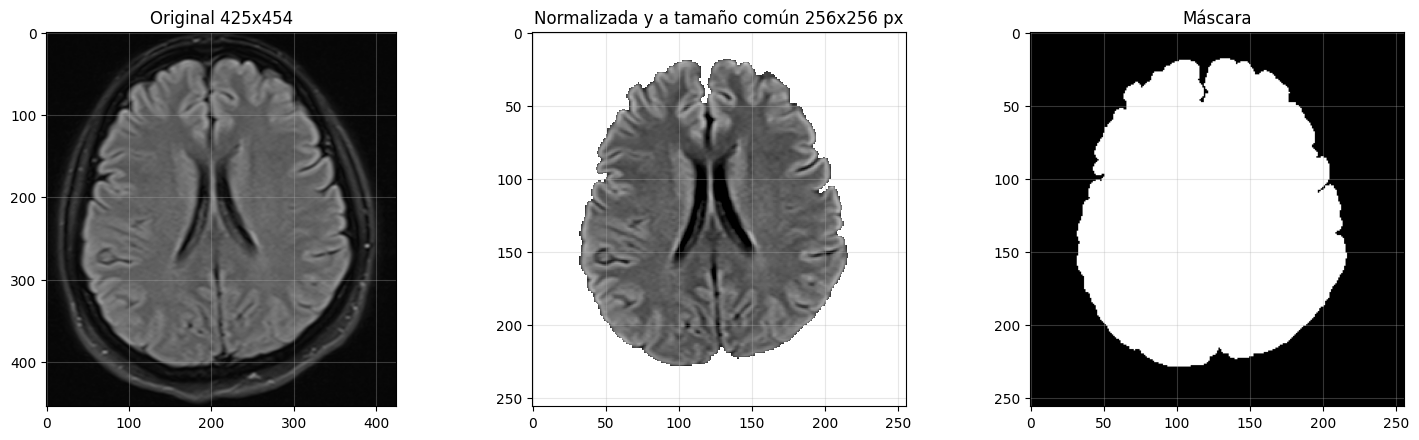

In [6]:
TAM = 256   # lado del cuadrado final (px)

def a_tamano_comun(arr, tam=TAM, orden=1):
    """Escala manteniendo la proporción (el lado mayor queda en `tam`) y centra en un cuadrado tam x tam, rellenando con ceros."""
    h, w = arr.shape
    f = tam / max(h, w)
    nh, nw = round(h * f), round(w * f)
    chico = resize(arr.astype(float), (nh, nw), order=orden, anti_aliasing=(orden > 0), preserve_range=True)
    out = np.zeros((tam, tam))
    y0, x0 = (tam - nh) // 2, (tam - nw) // 2
    out[y0:y0 + nh, x0:x0 + nw] = chico
    return out

z_final = a_tamano_comun(np.where(m4, z, 0))          # imagen normalizada (0 fuera de la máscara)
m_final = a_tamano_comun(m4, orden=0) > 0.5           # máscara, con interpolación de vecino más cercano

print(f"Antes: {img.shape[::-1]} (ancho x alto) -> Después: {z_final.shape[::-1]}")

fig, axs = plt.subplots(1, 3, figsize=(15, 4.5), gridspec_kw={"width_ratios": [1, 1, 1]})
axs[0].imshow(img, cmap="gray", vmin=0, vmax=255); axs[0].set_title(f"Original {img.shape[1]}x{img.shape[0]}")
axs[1].imshow(np.where(m_final, z_final, np.nan), cmap="gray", vmin=-3, vmax=5); axs[1].set_title(f"Normalizada y a tamaño común {TAM}x{TAM} px")
axs[2].imshow(m_final, cmap="gray"); axs[2].set_title("Máscara")
for a in axs:
    a.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

&ensp; Las imágenes del dataset tienen dimensiones heterogéneas y no se dispone del espaciado de píxel. Para poder aplicar los mismos algoritmos a todos los cortes, cada imagen normalizada se lleva a un cuadrado de **256 × 256 px**: se escala manteniendo la proporción, de modo que el lado mayor mida 256 px (interpolación bilineal), y se centra rellenando con ceros. La máscara se escala con interpolación de vecino más cercano para conservarla binaria. Así se evita deformar el cerebro, que ocurriría al estirar la imagen a un cuadrado sin tener en cuenta su proporción.

**Limitaciones.** La reducción a 256 px puede disminuir el tamaño en píxeles de las lesiones más pequeñas; el parámetro es ajustable si resultara un problema. Además, los valores fuera de la máscara no tienen significado, por lo que todos los cálculos posteriores deben restringirse a la máscara.